In [15]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [17]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

df.columns = df.columns.str.lower().str.replace(' ', '_')

string_columns = list(df.dtypes[df.dtypes == 'object'].index)

for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.churn = (df.churn == 'yes').astype(int)

In [18]:
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full, test_size=0.33, random_state=11)

y_train = df_train.churn.values
y_val = df_val.churn.values

del df_train['churn']
del df_val['churn']

In [19]:
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',
               'phoneservice', 'multiplelines', 'internetservice',
               'onlinesecurity', 'onlinebackup', 'deviceprotection',
               'techsupport', 'streamingtv', 'streamingmovies',
               'contract', 'paperlessbilling', 'paymentmethod']
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [21]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
dv.fit(train_dict)

X_train = dv.transform(train_dict)

In [23]:

import pandas as pd

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["converted"].value_counts())

display(df.head())


Dataset shape: (5000, 9)

Target distribution:
converted
1    2883
0    2117
Name: count, dtype: int64


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [25]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Use the new Course Lead Scoring dataset
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

# Check the target variable
print("Target distribution:")
print(df["converted"].value_counts())

# Split features and target
X = df.drop(columns=["converted"]).copy()
y = df["converted"].astype(int)

# Split into training and validation sets
X_train_df, X_val_df, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

# Handle missing values
X_train_df = X_train_df.fillna(0)
X_val_df = X_val_df.fillna(0)

# Convert categorical features to numerical features
dv = DictVectorizer(sparse=False)

train_dicts = X_train_df.to_dict(orient="records")
val_dicts = X_val_df.to_dict(orient="records")

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Train logistic regression model
model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=1
)

model.fit(X_train, y_train)

print("\nModel trained successfully!")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Classes:", model.classes_)


Target distribution:
converted
1    2883
0    2117
Name: count, dtype: int64

Model trained successfully!
Training shape: (4000, 28)
Validation shape: (1000, 28)
Classes: [0 1]


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [26]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Standardise the training and validation features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Train logistic regression on scaled features
model_scaled = LogisticRegression(
    solver="lbfgs",
    max_iter=2000,
    random_state=1
)

model_scaled.fit(X_train_scaled, y_train)

print("Model trained successfully!")
print("Iterations used:", model_scaled.n_iter_)
print("Classes:", model_scaled.classes_)


Model trained successfully!
Iterations used: [18]
Classes: [0 1]


In [27]:

from sklearn.metrics import roc_auc_score, accuracy_score

# Predicted probabilities of conversion
y_pred = model_scaled.predict_proba(X_val_scaled)[:, 1]

# Calculate evaluation metrics
auc = roc_auc_score(y_val, y_pred)

accuracy = accuracy_score(
    y_val,
    y_pred >= 0.5
)

print(f"Validation ROC AUC: {auc:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")


Validation ROC AUC: 0.8078
Validation Accuracy: 0.7180


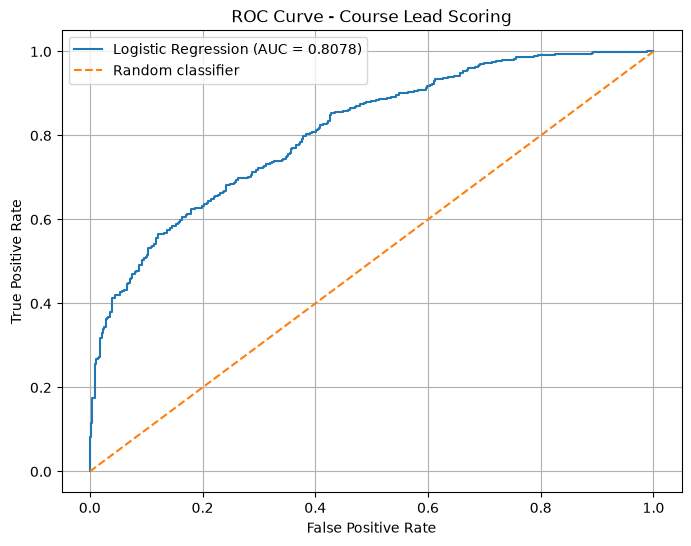

In [28]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Course Lead Scoring")
plt.legend()
plt.grid(True)
plt.show()


In [29]:
# Accuracy

In [30]:
y_pred = model.predict_proba(X_val)[:, 1]
churn = y_pred >= 0.5
(churn == y_val).mean()

np.float64(0.716)

In [31]:

import numpy as np
from sklearn.metrics import accuracy_score

thresholds = np.linspace(0, 1, 11)

for threshold in thresholds:
    predictions = y_pred >= threshold
    accuracy = accuracy_score(y_val, predictions)

    print(f"{threshold:.2f}  {accuracy:.3f}")


0.00  0.577
0.10  0.594
0.20  0.646
0.30  0.696
0.40  0.720
0.50  0.716
0.60  0.708
0.70  0.688
0.80  0.626
0.90  0.514
1.00  0.423


In [32]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Use the standard 0.5 threshold
y_pred_binary = y_pred >= 0.5

# Calculate confusion matrix
cm = confusion_matrix(y_val, y_pred_binary)

cm_df = pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

display(cm_df)


,Predicted 0,Predicted 1
Actual 0,265,158
Actual 1,126,451


In [33]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Calculate evaluation metrics
precision = precision_score(y_val, y_pred_binary)
recall = recall_score(y_val, y_pred_binary)
f1 = f1_score(y_val, y_pred_binary)
accuracy = accuracy_score(y_val, y_pred_binary)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


Accuracy:  0.7160
Precision: 0.7406
Recall:    0.7816
F1 Score:  0.7605


,Threshold,False Positive Rate,True Positive Rate
0,inf,0.000000,0.000000
1,0.987523,0.000000,0.001733
2,0.933162,0.000000,0.081456
3,0.932095,0.002364,0.081456
4,0.923856,0.002364,0.110919
5,0.921833,0.004728,0.110919
6,0.893727,0.004728,0.181976
7,0.892219,0.007092,0.181976
8,0.887058,0.007092,0.197574
9,0.886591,0.009456,0.197574


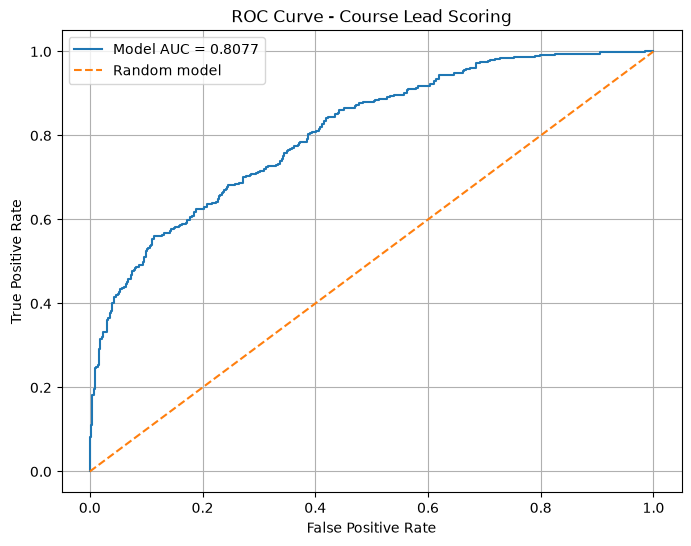

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

# Display some ROC threshold values
roc_table = pd.DataFrame({
    "Threshold": thresholds,
    "False Positive Rate": fpr,
    "True Positive Rate": tpr
})

display(roc_table.head(10))

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Model AUC = {roc_auc_score(y_val, y_pred):.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random model")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Course Lead Scoring")
plt.legend()
plt.grid(True)
plt.show()


In [35]:

import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

auc_scores = []

for fold, (train_idx, val_idx) in enumerate(
    kfold.split(X_train, y_train), start=1
):
    X_tr = X_train[train_idx]
    X_vl = X_train[val_idx]

    y_tr = np.asarray(y_train)[train_idx]
    y_vl = np.asarray(y_train)[val_idx]

    # Fit scaling independently within each fold
    fold_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            random_state=1
        )
    )

    fold_model.fit(X_tr, y_tr)

    y_prob = fold_model.predict_proba(X_vl)[:, 1]
    fold_auc = roc_auc_score(y_vl, y_prob)

    auc_scores.append(fold_auc)
    print(f"Fold {fold}: AUC = {fold_auc:.4f}")

print("\nMean AUC:", round(np.mean(auc_scores), 4))
print("Standard deviation:", round(np.std(auc_scores), 4))


Fold 1: AUC = 0.7912
Fold 2: AUC = 0.7851
Fold 3: AUC = 0.7736
Fold 4: AUC = 0.8194
Fold 5: AUC = 0.7742

Mean AUC: 0.7887
Standard deviation: 0.0167


In [36]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

# Fill missing values according to homework
for col in df.columns:
    if col == "converted":
        continue
    if df[col].dtype == "object":
        df[col] = df[col].fillna("NA")
    else:
        df[col] = df[col].fillna(0.0)

# Official homework split
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train["converted"].values
y_val = df_val["converted"].values

print("Training rows:", len(df_train))
print("Validation rows:", len(df_val))
print("Test rows:", len(df_test))


Training rows: 3000
Validation rows: 1000
Test rows: 1000


In [37]:

# Homework Question 1

numerical = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

auc_results = {}

for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    auc_results[col] = auc
    print(f"{col}: {auc:.4f}")

best_feature = max(auc_results, key=auc_results.get)

print("\nQuestion 1 answer:", best_feature)


lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082

Question 1 answer: lead_score


In [38]:

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Prepare training and validation features
X_train_df = df_train.drop(columns=["converted"])
X_val_df = df_val.drop(columns=["converted"])

train_dicts = X_train_df.to_dict(orient="records")
val_dicts = X_val_df.to_dict(orient="records")

# One-hot encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Train model using official homework parameters
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

# Predict conversion probabilities
y_pred = model.predict_proba(X_val)[:, 1]

# Calculate validation AUC
auc = roc_auc_score(y_val, y_pred)

print(f"Validation AUC: {auc:.4f}")
print(f"Rounded AUC: {auc:.3f}")
print("Classes:", model.classes_)


Validation AUC: 0.7319
Rounded AUC: 0.732
Classes: [0 1]


Question 3 results
Intersection threshold: 0.63
Precision: 0.7332
Recall: 0.7270


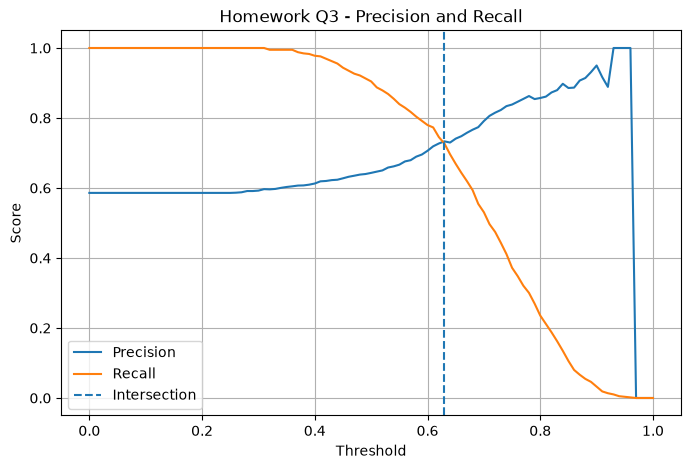

In [39]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.linspace(0, 1, 101)

precisions = []
recalls = []

for t in thresholds:
    predictions = y_pred >= t

    p = precision_score(
        y_val, predictions, zero_division=0
    )
    r = recall_score(
        y_val, predictions, zero_division=0
    )

    precisions.append(p)
    recalls.append(r)

precisions = np.array(precisions)
recalls = np.array(recalls)

# Exclude thresholds where both are zero
valid = (precisions != 0) | (recalls != 0)

differences = np.abs(precisions - recalls)
differences[~valid] = np.inf

best_idx = np.argmin(differences)

print("Question 3 results")
print(f"Intersection threshold: {thresholds[best_idx]:.2f}")
print(f"Precision: {precisions[best_idx]:.4f}")
print(f"Recall: {recalls[best_idx]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.axvline(
    thresholds[best_idx],
    linestyle="--",
    label="Intersection"
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Homework Q3 - Precision and Recall")
plt.legend()
plt.grid(True)
plt.show()


Question 4 results
Best threshold: 0.41
Maximum F1 score: 0.7576


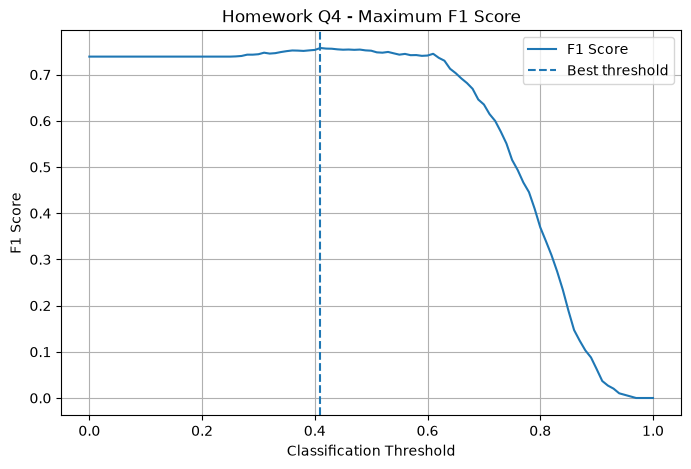

In [40]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

thresholds = np.linspace(0, 1, 101)

f1_scores = []

for t in thresholds:
    predictions = y_pred >= t
    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )
    f1_scores.append(f1)

f1_scores = np.array(f1_scores)

best_idx = np.argmax(f1_scores)

print("Question 4 results")
print(f"Best threshold: {thresholds[best_idx]:.2f}")
print(f"Maximum F1 score: {f1_scores[best_idx]:.4f}")

# Plot F1 against threshold
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores, label="F1 Score")

plt.axvline(
    thresholds[best_idx],
    linestyle="--",
    label="Best threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("F1 Score")
plt.title("Homework Q4 - Maximum F1 Score")
plt.legend()
plt.grid(True)
plt.show()


In [41]:

from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for fold, (train_idx, val_idx) in enumerate(
    kfold.split(df_full_train), start=1
):
    # Select data for this fold
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]

    y_tr = fold_train["converted"].values
    y_vl = fold_val["converted"].values

    # Prepare features
    train_dicts = fold_train.drop(
        columns=["converted"]
    ).to_dict(orient="records")

    val_dicts = fold_val.drop(
        columns=["converted"]
    ).to_dict(orient="records")

    # Encode each fold independently
    dv_fold = DictVectorizer(sparse=False)

    X_tr = dv_fold.fit_transform(train_dicts)
    X_vl = dv_fold.transform(val_dicts)

    # Train model
    model_fold = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(X_tr, y_tr)

    # Evaluate AUC
    y_prob = model_fold.predict_proba(X_vl)[:, 1]
    fold_auc = roc_auc_score(y_vl, y_prob)

    scores.append(fold_auc)

    print(f"Fold {fold}: AUC = {fold_auc:.4f}")

print("\nQuestion 5 results")
print(f"Mean AUC: {np.mean(scores):.4f}")
print(f"Standard deviation: {np.std(scores):.4f}")
print(f"Rounded std: {np.std(scores):.3f}")


Fold 1: AUC = 0.7305
Fold 2: AUC = 0.7297
Fold 3: AUC = 0.7363
Fold 4: AUC = 0.7413
Fold 5: AUC = 0.7210

Question 5 results
Mean AUC: 0.7318
Standard deviation: 0.0068
Rounded std: 0.007


In [42]:

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

C_values = [0.000001, 0.001, 1]
results = []

for C in C_values:
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        y_tr = fold_train["converted"].values
        y_vl = fold_val["converted"].values

        train_dicts = fold_train.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        val_dicts = fold_val.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        dv = DictVectorizer(sparse=False)

        X_tr = dv.fit_transform(train_dicts)
        X_vl = dv.transform(val_dicts)

        model = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model.fit(X_tr, y_tr)

        y_prob = model.predict_proba(X_vl)[:, 1]

        scores.append(roc_auc_score(y_vl, y_prob))

    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)

    results.append({
        "C": C,
        "Mean AUC": mean_auc,
        "Std AUC": std_auc
    })

results_df = pd.DataFrame(results)

display(results_df)

# Highest rounded mean, lowest std, then smallest C
best = results_df.sort_values(
    ["Mean AUC", "Std AUC", "C"],
    ascending=[False, True, True]
).iloc[0]

print("\nQuestion 6 answer:", best["C"])


,C,Mean AUC,Std AUC
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007



Question 6 answer: 0.001
